# Importing, processing, and exporting micrographs

This notebook covers the handling of micrographs from the Main Lab Microscope, which exports a JPEG of 2448 x 2048 px, normally with an info bar along the bottom of the image showing the stage position, sample name, and scalebar. These files are handled by the `Micrograph` loader.

When the loader is called, a few things happen. The image is first checked that it has the right shape consistent with micrographs taken with the microscope in the main lab. Then the loader checks for the information bar that comes with saved micrographs from the main lab microscope and obtains the magnification saved with the image.

> As a little aside, we will explain how the loader obtains the magnification recorded in the image. Our images saved all have the same information: the X coordinate, the Y coordinate, sample name, and scalebar comprising a line and value. The position of "X" is always the same in all the images, so the loader checks that the image provided at loadtime has this "X" text at the known coordinates. If it does not, it loads the image but with magnification and `pixel_size` unknown. If it passes this check, it looks at the value assigned to the scalebar on the right of the image. Using a mask it has loaded (in the form of an `.npz` file obtained from some example images), it performs a check if the shape of the text in this value position matches any of the stored masks. It then assigns a magnification based on this information. If the label matches none of the stored masks — for example because a long sample name covers it — the loader stops with an error and asks for magnification= rather than guessing.

Thus, in images where the scalebar and value are both visible and unobstructed, the loader is able to infer the magnification at load time. Whether or not the value assigned to the scalebar is indeed correct, due to a faulty save, for example, is not something the loader would know. The user must pay attention to this fact: the loader alone cannot infer if the image saved contains the wrong scalebar. We show how to override this in section 4.

As a caveat, the pixel sizes the loader assigns come from the **nominal objective magnification**, which are only true in theory. Real pixel sizes may differ by a few percent. Measure a known structure if lengths matter (see section 3).

Before running this notebook:
- Make sure the notebook is run from `examples/` because the paths are relative to that folder
- The scale bar needs the matplotlib-scalebar package. If `plot_micrograph` fails with `No module named 'matplotlib_scalebar'`, run `pip install -e .` again from the repository folder.

A quick reference table of the arguments of `Micrograph`:

| Argument | Use when |
| -------- | -------- |
| `magnification=` | the image has no info bar, or when you want to state it | 
| `label_reads=` | the label is wrong; give the true `magnification=` plus what the label shows | 
| `pixel_size=` | you measured um per pixel from a known structure | 
| `remove_info_bar=True` | you want the bottom info bar (bottom 46 px) gone from `img` |

The outline of this notebook:
1. Load and inspect an image
2. Plot an image -- `imshow` vs `plot_micrograph`
3. Images without an info bar
4. Images with a wrong label
5. Arguments and images rejected by `Micrograph`

## 1. Load and inspect an image

In [1]:
import leman as lm
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path
path = Path('./data/optical-microscope')

We load our image. 

In [2]:
img = lm.Micrograph(
    path = path / "100x_example_1.jpg" # path to the file
    # magnification = 100 The magnification of the objective used to capture the image. Possible Values: 5, 10, 20, 50, 100. 
    # label_reads = 5, 10, 20, 50, 100. What the wrong label shows; only together with magnification=
    # pixel_size = float. um per pixel if known from the structure size or calibration. 
    # remove_info_bar = bool. Drops the bottom 46 rows of the image which contains the information bar.
    #                         When True, img_raw keeps full frame, and only img is cut. The removed rows also contain sample, because the bar is see-through.
    #                         On an image with no bar, remove_info_bar=True is refused.
    )

We have a couple of attributes in this object:

In [3]:
print(img)

Micrograph — 2448 × 2048 px
  File          : data\optical-microscope\100x_example_1.jpg
  Info bar      : kept
  Magnification : 100× (read from the label)
  Pixel size    : 0.068871 µm/px (nominal)



In [4]:
print(f"The dimensions of the image are: {img.img_raw.shape}")
print(f"The image has an information bar? {img.has_info_bar}")
print(f"The label magnification read by the loader is {img.label_magnification}")
print(f"The magnification in use is {img.magnification}, taken from the label because we did not pass one.")

The dimensions of the image are: (2048, 2448, 3)
The image has an information bar? True
The label magnification read by the loader is 100
The magnification in use is 100, taken from the label because we did not pass one.


## 2. Plot an image

We could of course plot the image as we normally would with `matplotlib`, like

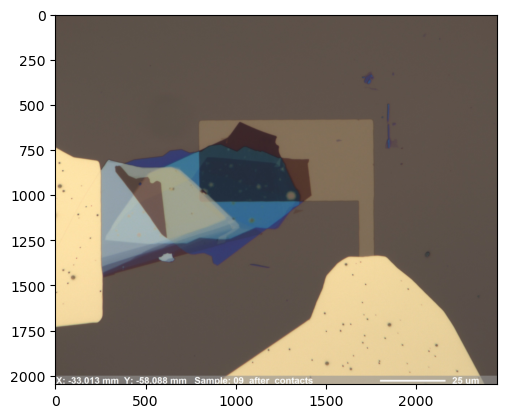

In [ ]:
plt.imshow(img.img_raw);

But there's a neater way to do it with `leman` which removes all the tick labels.

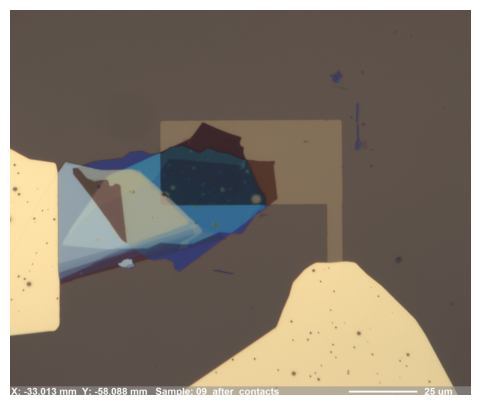

In [6]:
fig, ax, *_ = lm.plotting.plot_micrograph(
    micrograph = img,
    ax = None, # provide an ax to plot
    # figsize = (6,5) # default
    scalebar = False
    )

Now we're going to edit the image to drop the information bar at the bottom and add a scalebar. This can be done fairly easily with the library.

In [7]:
img = lm.Micrograph(
    path = path / "100x_example_1.jpg", # path to the file
    # magnification = 100 The magnification of the objective used to capture the image. Possible Values: 5, 10, 20, 50, 100. 
    # label_reads = 5, 10, 20, 50, 100. What the wrong label shows; only together with magnification=
    # pixel_size = float. um per pixel if known from the structure size or calibration. 
    remove_info_bar = True # Drops the bottom 46 rows of the image which contains the information bar.
    )

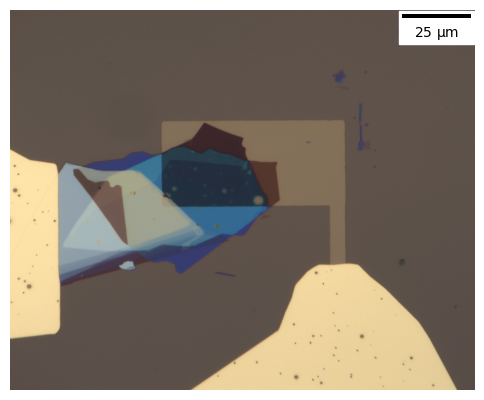

In [8]:
fig, ax, *_ = lm.plotting.plot_micrograph(
    micrograph = img,
    scalebar = True
    )

We can also customise the properties of the scalebar. A quick guide on the properties available for editing can be found [here](https://kolibril13.github.io/plywood-gallery-matplotlib-scalebar/). And of course, we can save our image as we do typically.

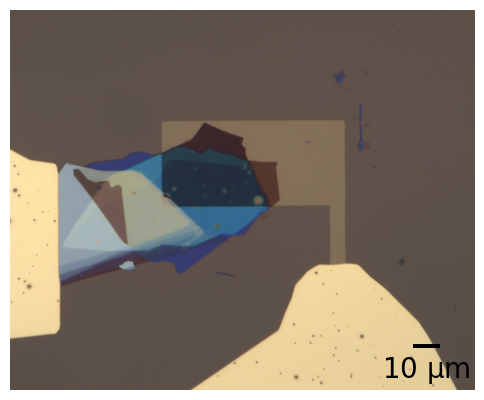

In [9]:
fig, ax, *_ = lm.plotting.plot_micrograph(
    micrograph = img,
    scalebar = True,
    location = "lower right",
    color = "black",
    box_alpha = 0,
    fixed_units = "um",
    fixed_value= 10,
    font_properties = {"size" : 20}
    )

# fig.savefig('device_img.png', dpi = 300, bbox_inches = 'tight')

We can also plot multiple images next to each other, which could be useful for creating figures. Here, we plot the bright field and dark field images side-by-side.

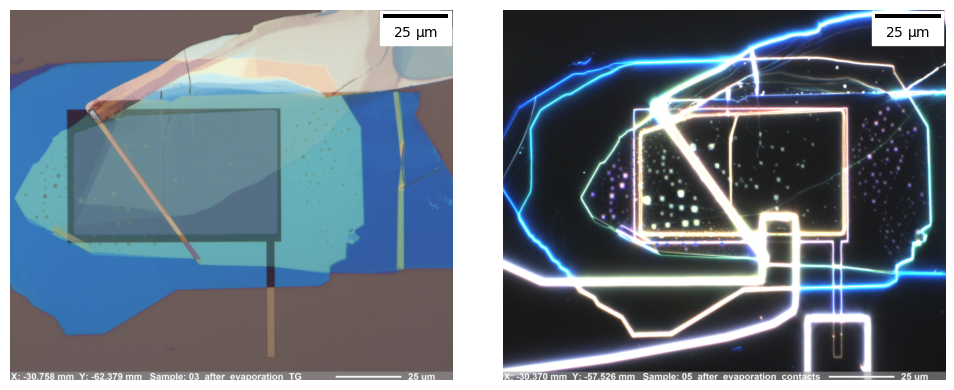

In [10]:
micrograph_arr = [lm.Micrograph(path = path/f"100x_example_{i}.jpg") for i in (4,6)]

fig, ax = plt.subplots(1,2, figsize =(10,4))

for a,m in zip(ax, micrograph_arr):
    lm.plotting.plot_micrograph(m, ax=a)

fig.tight_layout()

## 3. Images without an info bar

There are two kinds of images we might take in the laboratory which do not have an information bar when saved: B&W images and images with a closed aperture. We have to provide the `magnification` or `pixel_size` for the scalebar.

Micrograph — 2448 × 2048 px
  File          : data\optical-microscope\BW_example_100x.jpg
  Info bar      : none
  Magnification : unknown
  Pixel size    : unknown — pass magnification= or pixel_size=



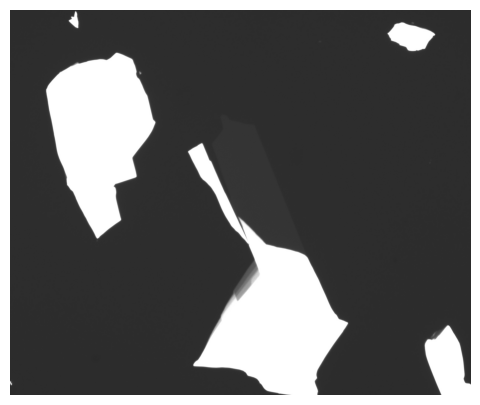

In [11]:
bw_img = lm.Micrograph(
    path = path / "BW_example_100x.jpg"
)

print(bw_img)

fig, ax, *_ = lm.plotting.plot_micrograph(bw_img, scalebar=False) #scalebar here must be false because we don't know our pixel_size

Here, we pass in the magnification used to obtain the image.

Micrograph — 2448 × 2048 px
  File          : data\optical-microscope\BW_example_100x.jpg
  Info bar      : none
  Magnification : 100× (declared)
  Pixel size    : 0.068871 µm/px (nominal)



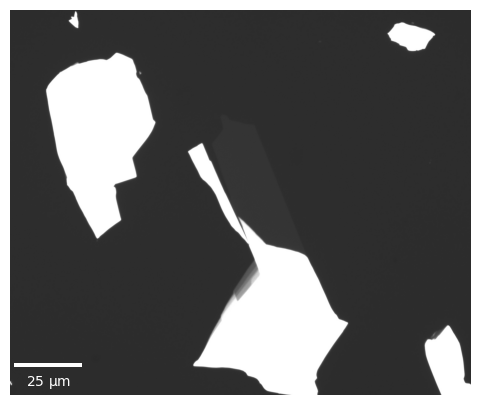

In [12]:
bw_img = lm.Micrograph(
    path = path / "BW_example_100x.jpg",
    magnification=100,
)

print(bw_img)

fig, ax, *_ = lm.plotting.plot_micrograph(bw_img, scalebar=True, color = 'white', location = 'lower left', box_alpha = 0)

Now an aperture image where we do not remember the magnification. Instead, we measure the pixel size from a known structure.

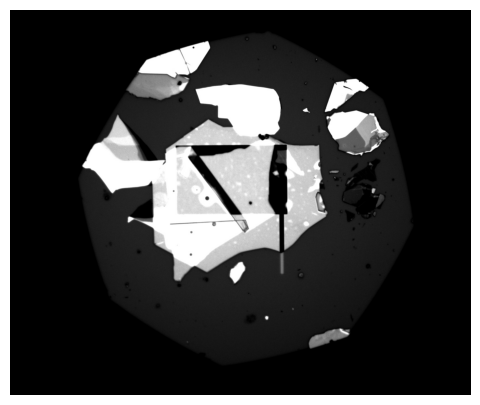

In [13]:
noscalebar_img = lm.Micrograph(
    path = path / 'aperture_example_50x.jpg'
)

fig, ax, *_ = lm.plotting.plot_micrograph(noscalebar_img, scalebar=False)

From the `.gds` file we have (not provided with the notebook), we know that the physical width of the gate is $80\;\mathrm{\mu m}$ which covers 587 pixels, which can be measured with Paint or an equivalent piece of software. With this, we can calculate our `pixel_size` for the plot.

Micrograph — 2448 × 2048 px
  File          : data\optical-microscope\aperture_example_50x.jpg
  Info bar      : none
  Magnification : unknown
  Pixel size    : 0.13629 µm/px (given)



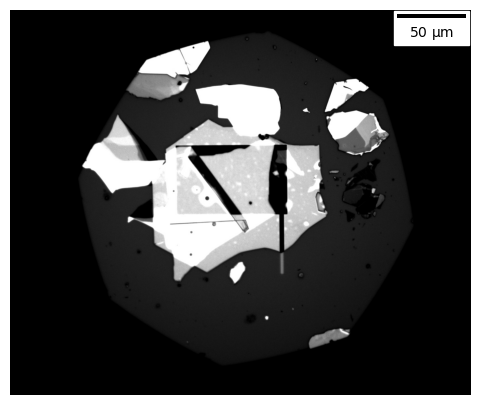

In [14]:
noscalebar_img = lm.Micrograph(
    path = path / 'aperture_example_50x.jpg',
    pixel_size = 80 / 587 # um per pixel
)
print(noscalebar_img)
fig, ax, *_ = lm.plotting.plot_micrograph(noscalebar_img, scalebar=True)

The `pixel_size` we obtained is `0.13629 µm/px`, about 1% smaller than the nominal value of `0.1377 µm/px`. This objective therefore behaves like ≈50.5x. The loader uses the nominal value whenever the pixel size comes from a magnification; measuring a known structure corrects this value.

`pixel_size=` replaces the nominal value and is not compared with the label. Be sure the value is right! As shown below, a wrong value gives a meaningless scale bar.

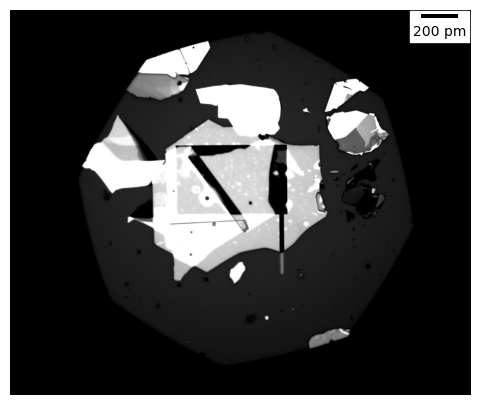

In [15]:
noscalebar_img = lm.Micrograph(
    path = path / "aperture_example_50x.jpg",
    pixel_size = 1e-6 # um per pixel
)

fig, ax, *_ = lm.plotting.plot_micrograph(noscalebar_img)

## 4. Images with a wrong label

We load a different image taken with the 50x objective:

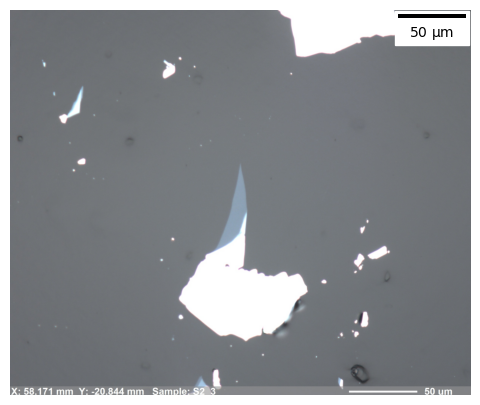

In [16]:
flake_img = lm.Micrograph(
    path = path/"50x_example_2.jpg"
)

fig, ax, *_ = lm.plotting.plot_micrograph(flake_img)

Now, for argument's sake, let's say we recorded the wrong magnification when we took the image. Instead of 50x as indicated by the scalebar, we actually used the 100x objective. In this case, the scalebar indicated in the image is wrong. Passing only the true magnification is refused:

In [17]:
try:
    flake_img = lm.Micrograph(
        path = path / "50x_example_2.jpg",
        magnification = 100
    )
except ValueError as err:
    print(f"ValueError: {err}")

ValueError: magnification=100, but the label in 'data\optical-microscope\50x_example_2.jpg' reads 50× (50 um). If the software was set to the wrong objective, pass magnification=100, label_reads=50.


And we get an error. This is intentional. For this override to function, the user must provide **the magnification actually used** and **what the wrong label shows**. The reasoning is as follows: if the cell is copied and run on another image, the override is refused unless that image's label also shows 50×. Through this, we try to reduce the propagation of errors when code is copied. We perform this override with:

Micrograph — 2448 × 2048 px
  File          : data\optical-microscope\50x_example_2.jpg
  Info bar      : kept
  Magnification : 100× (declared; label reads 50×)
  Pixel size    : 0.068871 µm/px (nominal)



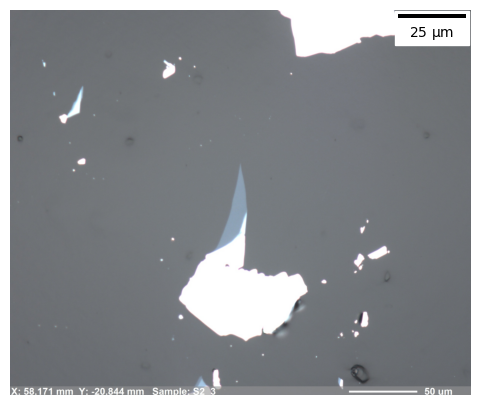

In [18]:
flake_img = lm.Micrograph(
    path = path / "50x_example_2.jpg",
    magnification = 100,
    label_reads = 50
)

print(flake_img)

fig, ax, *_ =  lm.plotting.plot_micrograph(flake_img)

The print statement shows the override: the label reads 50×, but the magnification in use, and so the pixel size, follow 100×.

## 5. Arguments and images rejected by `Micrograph`

`magnification=` and `pixel_size=` cannot be given together, since a measured pixel size and a nominal magnification may disagree:

In [19]:
try:
    bw_img = lm.Micrograph(
        path = path / "BW_example_100x.jpg",
        magnification = 100,
        pixel_size = 1e-6)
except ValueError as err:
    print(f"ValueError: {err}")

ValueError: Give magnification= or pixel_size=, not both: a measured pixel size and a nominal magnification can disagree.


Finally, we try out an image not captured with the main lab microscope. FYI: this was captured with transfer stage 2. The image in question is:

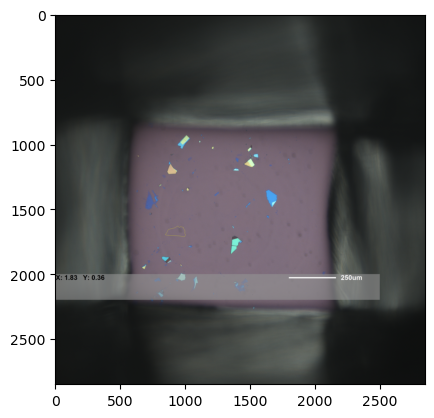

In [ ]:
bad_img = mpimg.imread(path/'example_reject.png')
plt.imshow(bad_img);

and when we try to load this with `Micrograph`, it is rejected because the shape of the image is different.

In [21]:
try: 
    lm.Micrograph(path/'example_reject.png')
except ValueError as err:
    print(f"ValueError: {err}")

ValueError: 'data\optical-microscope\example_reject.png' is 2848 × 2848 px; the main-lab microscope saves 2448 × 2048 px. The image is from another instrument, or was resized or cropped after export.
